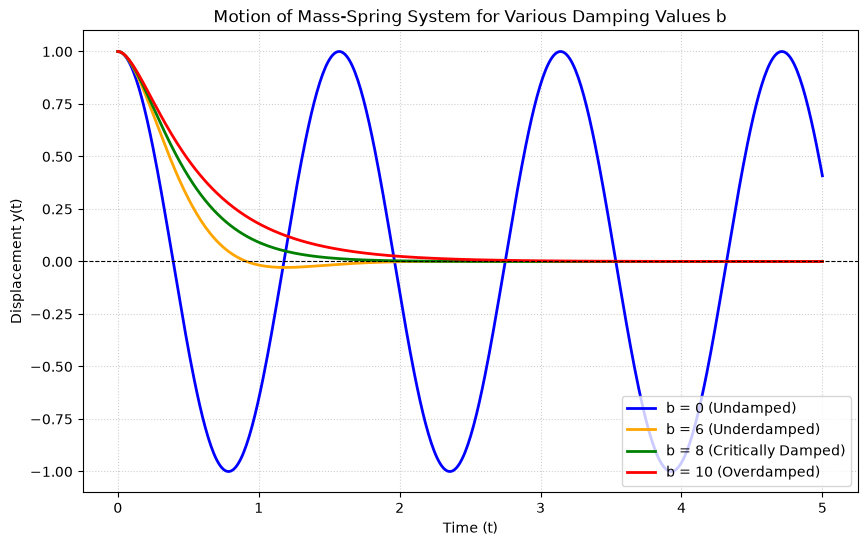

In [6]:
#THIS CELL COMPUTES THE PROBLEM AT SPECIFIED b VALUES
import numpy as np
import matplotlib.pyplot as plt

# 1. Define the independent time domain
t = np.linspace(0, 5, 500)

# 2. Define the exact analytical solutions calculated from Problem 3
# b = 0: Undamped
y_undamped = np.cos(4 * t)

# b = 6: Underdamped
y_underdamped = np.exp(-3 * t) * (np.cos(np.sqrt(7) * t) + (3 / np.sqrt(7)) * np.sin(np.sqrt(7) * t))

# b = 8: Critically Damped
y_critical = (1 + 4 * t) * np.exp(-4 * t)

# b = 10: Overdamped
y_overdamped = (4 / 3) * np.exp(-2 * t) - (1 / 3) * np.exp(-8 * t)

# 3. Structural graph plotting configuration
plt.figure(figsize=(10, 6))

plt.plot(t, y_undamped, label='b = 0 (Undamped)', color='blue', linewidth=2)
plt.plot(t, y_underdamped, label='b = 6 (Underdamped)', color='orange', linewidth=2)
plt.plot(t, y_critical, label='b = 8 (Critically Damped)', color='green', linewidth=2)
plt.plot(t, y_overdamped, label='b = 10 (Overdamped)', color='red', linewidth=2)

# 4. Labeling and formatting without any LaTeX symbols
plt.title('Motion of Mass-Spring System for Various Damping Values b')
plt.xlabel('Time (t)')
plt.ylabel('Displacement y(t)')
plt.axhline(0, color='black', linewidth=0.8, linestyle='--')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()

# 5. Display output window
plt.show()


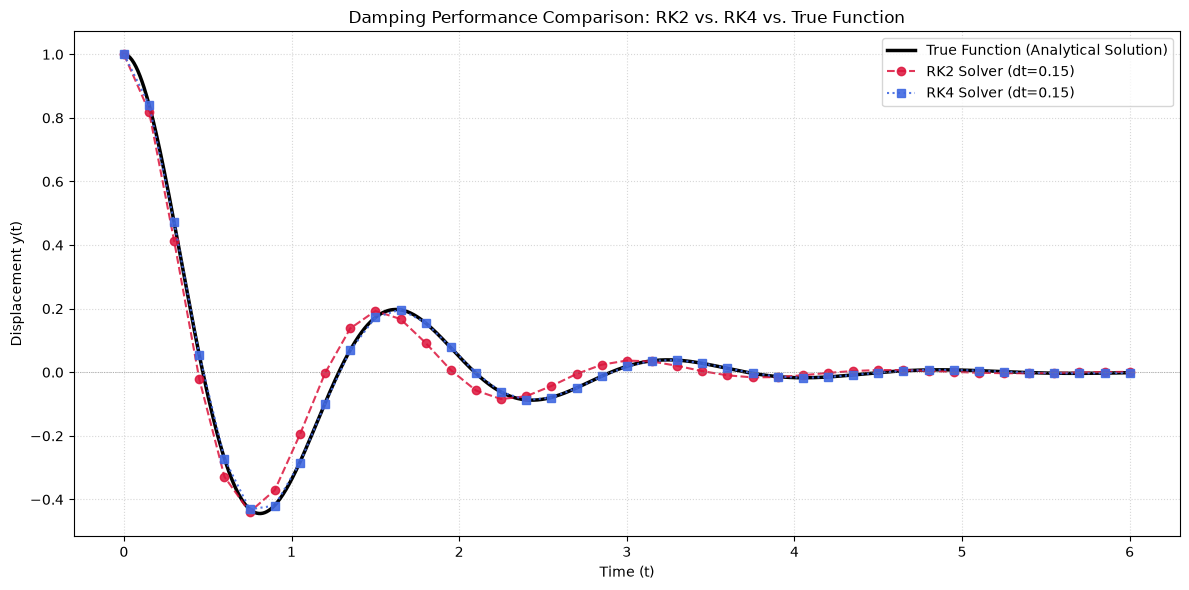

In [10]:
#THIS CELL COMPARES RK2 AND RK4 METHODS SIDE-BY-SIDE WITH THE TRUE FUNCTION
import numpy as np
import matplotlib.pyplot as plt

# 1. Define Derivative State Function (System of first-order ODEs)
def get_derivatives(y, v, b, k, m):
    """Returns dy/dt and dv/dt for the mass-spring-damper system."""
    dy_dt = v
    dv_dt = -(b * v + k * y) / m
    return dy_dt, dv_dt

# 2. Runge-Kutta 2nd Order Solver (Heun's Method / Predictor-Corrector)
def rk2_simulation(m, b, k, y0, v0, t_max, dt):
    num_steps = int(t_max / dt) + 1
    t = np.linspace(0, t_max, num_steps)
    y = np.zeros(num_steps)
    v = np.zeros(num_steps)
    
    y[0], v[0] = y0, v0
    
    for i in range(num_steps - 1):
        dy1, dv1 = get_derivatives(y[i], v[i], b, k, m)
        y_pred = y[i] + dt * dy1
        v_pred = v[i] + dt * dv1
        
        dy2, dv2 = get_derivatives(y_pred, v_pred, b, k, m)
        
        y[i+1] = y[i] + 0.5 * dt * (dy1 + dy2)
        v[i+1] = v[i] + 0.5 * dt * (dv1 + dv2)
        
    return t, y

# 3. Runge-Kutta 4th Order Solver
def rk4_simulation(m, b, k, y0, v0, t_max, dt):
    num_steps = int(t_max / dt) + 1
    t = np.linspace(0, t_max, num_steps)
    y = np.zeros(num_steps)
    v = np.zeros(num_steps)
    
    y[0], v[0] = y0, v0
    
    for i in range(num_steps - 1):
        dy1, dv1 = get_derivatives(y[i], v[i], b, k, m)
        dy2, dv2 = get_derivatives(y[i] + 0.5*dt*dy1, v[i] + 0.5*dt*dv1, b, k, m)
        dy3, dv3 = get_derivatives(y[i] + 0.5*dt*dy2, v[i] + 0.5*dt*dv2, b, k, m)
        dy4, dv4 = get_derivatives(y[i] + dt*dy3, v[i] + dt*dv3, b, k, m)
        
        y[i+1] = y[i] + (dt / 6.0) * (dy1 + 2*dy2 + 2*dy3 + dy4)
        v[i+1] = v[i] + (dt / 6.0) * (dv1 + 2*dv2 + 2*dv3 + dv4)
        
    return t, y

# 4. Automatically Compute the True Analytical Solution
def analytical_solution(m, b, k, y0, v0, t):
    """Calculates the exact theoretical solution based on system conditions."""
    disc = b**2 - 4*m*k
    
    # Case 1: Undamped System (b = 0)
    if b == 0:
        w0 = np.sqrt(k / m)
        c1 = y0
        c2 = v0 / w0
        return c1 * np.cos(w0 * t) + c2 * np.sin(w0 * t)
        
    # Case 2: Underdamped System
    elif disc < 0:
        alpha = b / (2 * m)
        wd = np.sqrt(4 * m * k - b**2) / (2 * m)
        c1 = y0
        c2 = (v0 + alpha * y0) / wd
        return np.exp(-alpha * t) * (c1 * np.cos(wd * t) + c2 * np.sin(wd * t))
        
    # Case 3: Critically Damped System
    elif disc == 0:
        alpha = b / (2 * m)
        c1 = y0
        c2 = v0 + alpha * y0
        return (c1 + c2 * t) * np.exp(-alpha * t)
        
    # Case 4: Overdamped System
    else:
        r1 = (-b + np.sqrt(disc)) / (2 * m)
        r2 = (-b - np.sqrt(disc)) / (2 * m)
        c2 = (v0 - r1 * y0) / (r2 - r1)
        c1 = y0 - c2
        return c1 * np.exp(r1 * t) + c2 * np.exp(r2 * t)

# ==========================================
# SYSTEM PARAMETERS SETUP (Change these to test any case!)
# ==========================================
m_param = 1.0       # Mass
b_param = 2.0       # Damping coefficient (b=0: undamped, b=2: underdamped, b=8: critical, b=10: overdamped)
k_param = 16.0      # Spring constant
y0_param = 1.0      # Initial position
v0_param = 0.0      # Initial velocity
t_end = 6.0         # Total duration to track

# Larger step size makes tracking variations between models visible
dt_param = 0.15      

# Execute Simulations
t_rk2, y_rk2 = rk2_simulation(m_param, b_param, k_param, y0_param, v0_param, t_end, dt_param)
t_rk4, y_rk4 = rk4_simulation(m_param, b_param, k_param, y0_param, v0_param, t_end, dt_param)

# Generate fine grid for True Function
t_true = np.linspace(0, t_end, 1000)
y_true = analytical_solution(m_param, b_param, k_param, y0_param, v0_param, t_true)

# ==========================================
# PLOTTING
# ==========================================
plt.figure(figsize=(12, 6))

# Plot tracks
plt.plot(t_true, y_true, color='black', linewidth=2.5, label='True Function (Analytical Solution)')
plt.plot(t_rk2, y_rk2, color='crimson', marker='o', linestyle='--', label=f'RK2 Solver (dt={dt_param})', alpha=0.85)
plt.plot(t_rk4, y_rk4, color='royalblue', marker='s', linestyle=':', label=f'RK4 Solver (dt={dt_param})', alpha=0.9)

# Plot details
plt.title('Damping Performance Comparison: RK2 vs. RK4 vs. True Function')
plt.xlabel('Time (t)')
plt.ylabel('Displacement y(t)')
plt.axhline(0, color='gray', linewidth=0.5, linestyle=':')
plt.grid(True, linestyle=':', alpha=0.5)
plt.legend(loc='upper right')

plt.tight_layout()
plt.show()




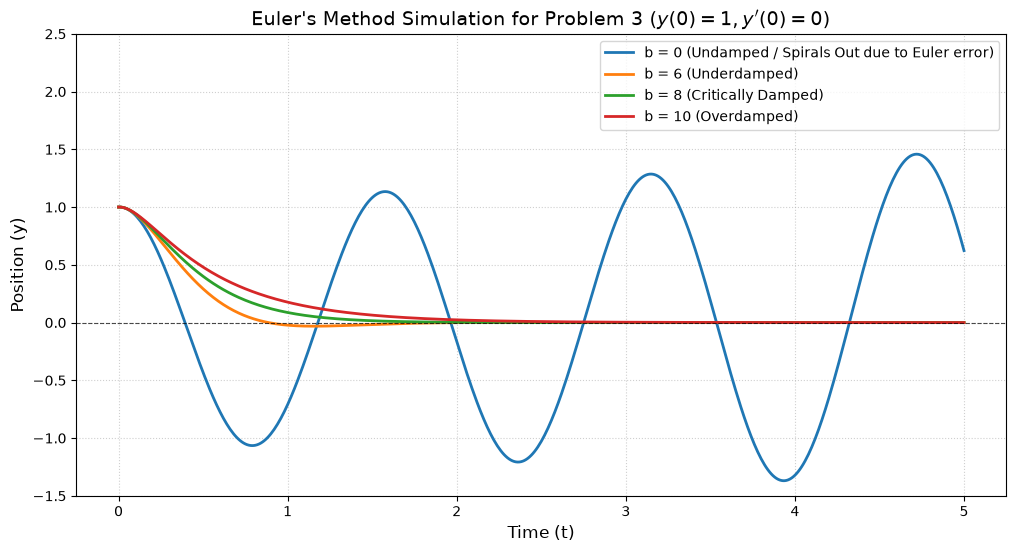

In [1]:
#THIS CELL SHOWS AN ENERGY EXPLOSION USING EULER'S METHOD!!!
import numpy as np
import matplotlib.pyplot as plt

# 1. Define the first-order system function
# x[0] = position (y), x[1] = velocity (y')
def system_derivatives(x, b):
    x1_dot = x[1]
    x2_dot = -16 * x[0] - b * x[1]
    return np.array([x1_dot, x2_dot])

# 2. Simulation parameters
t_start = 0.0
t_end = 5.0
h = 0.01  # Time step size
t_steps = np.arange(t_start, t_end + h, h)

# The four damping values requested in Problem 3
b_values = [0, 6, 8, 10]
labels = [
    "b = 0 (Undamped / Spirals Out due to Euler error)",
    "b = 6 (Underdamped)",
    "b = 8 (Critically Damped)",
    "b = 10 (Overdamped)"
]

# 3. Set up the plotting environment
plt.figure(figsize=(12, 6))

# 4. Loop through each damping value and apply Euler's Method
for b, label in zip(b_values, labels):
    # Initialize arrays to store position solutions
    positions = np.zeros(len(t_steps))
    
    # Set Initial Conditions: y(0) = 1, y'(0) = 0
    current_state = np.array([1.0, 0.0])
    positions[0] = current_state[0]
    
    # Time-marching loop using Euler's rule: x_(n+1) = x_n + h * f(t_n, x_n)
    for i in range(1, len(t_steps)):
        derivatives = system_derivatives(current_state, b)
        current_state = current_state + h * derivatives
        positions[i] = current_state[0]
        
    # Plot the position over time for this b value
    plt.plot(t_steps, positions, label=label, linewidth=2)

# 5. Final plot adjustments
plt.title("Euler's Method Simulation for Problem 3 ($y(0)=1, y'(0)=0$)", fontsize=14)
plt.xlabel("Time (t)", fontsize=12)
plt.ylabel("Position (y)", fontsize=12)
plt.axhline(0, color='black', linestyle='--', linewidth=0.8, alpha=0.7)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=10, loc="upper right")
plt.ylim(-1.5, 2.5)  # Expanded upper limit to capture the b=0 Euler expansion artifact
plt.show()


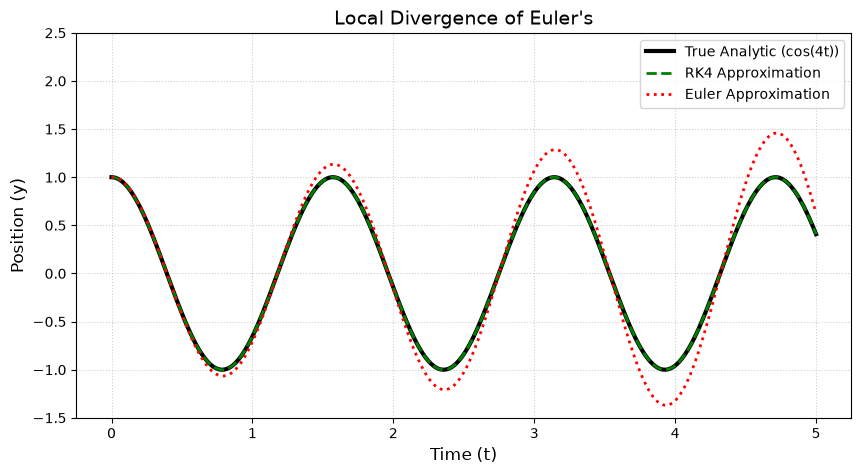

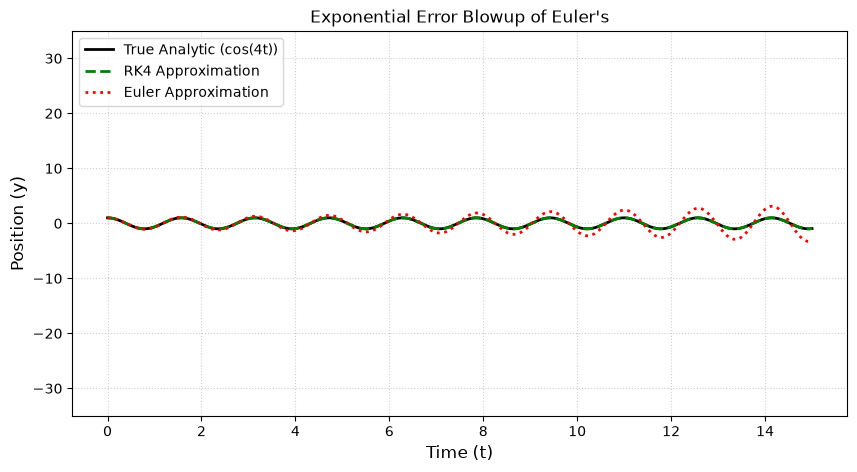

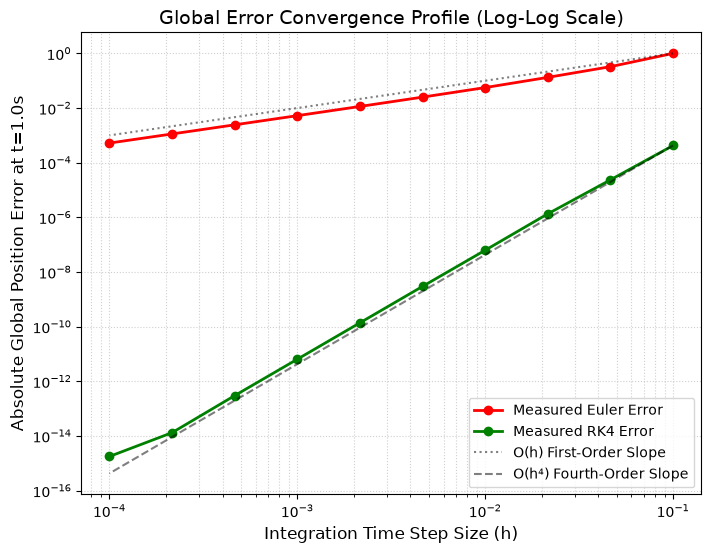

In [4]:
#THIS CELL SHOWS THE EULER EXPLOSION EVEN MORE CLEARLY!!!
import numpy as np
import matplotlib.pyplot as plt

# 1. Define the first-order system derivatives
def system_derivatives(x, b):
    x1_dot = x[1] # velocity (x2)
    x2_dot = -16 * x[0] - b * x[1] # acceleration
    return np.array([x1_dot, x2_dot])

# 2. Implement a single step of RK4
def rk4_step(x, b, h):
    k1 = system_derivatives(x, b)
    k2 = system_derivatives(x + 0.5 * h * k1, b)
    k3 = system_derivatives(x + 0.5 * h * k2, b)
    k4 = system_derivatives(x + h * k3, b)
    return x + (h / 6.0) * (k1 + 2*k2 + 2*k3 + k4)

# 3. True Analytical Solution for b = 0, y(0) = 1, y'(0) = 0
def true_solution(t):
    return np.cos(4 * t)

# 4. Simulation Parameters
h = 0.01  # Time step size
t_short = np.arange(0.0, 5.0 + h, h)    # Timeline for Figure 1
t_long = np.arange(0.0, 15.0 + h, h)    # Timeline for Figure 2

# =====================================================================
# FIGURE 1: Standard View (0 to 5 seconds)
# =====================================================================
# Run Euler for b = 0
y_euler_short = np.zeros(len(t_short))
state_euler = np.array([1.0, 0.0]) 
y_euler_short[0] = state_euler[0]  

for i in range(1, len(t_short)):
    state_euler = state_euler + h * system_derivatives(state_euler, b=0)
    y_euler_short[i] = state_euler[0] 

# Run RK4 for b = 0
y_rk4_short = np.zeros(len(t_short))
state_rk4 = np.array([1.0, 0.0])
y_rk4_short[0] = state_rk4[0]

for i in range(1, len(t_short)):
    state_rk4 = rk4_step(state_rk4, b=0, h=h)
    y_rk4_short[i] = state_rk4[0]

# Render Figure 1 using clean axis framework
fig1, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(t_short, true_solution(t_short), 'k-', linewidth=3, label="True Analytic (cos(4t))")
ax1.plot(t_short, y_rk4_short, 'g--', linewidth=2, label="RK4 Approximation")
ax1.plot(t_short, y_euler_short, 'r:', linewidth=2, label="Euler Approximation")
ax1.set_title("Local Divergence of Euler's", fontsize=14)
ax1.set_xlabel("Time (t)", fontsize=12)
ax1.set_ylabel("Position (y)", fontsize=12)
ax1.set_ylim(-1.5, 2.5)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc="upper right")
plt.show()

# =====================================================================
# FIGURE 2: Zoomed Out View (0 to 15 seconds)
# =====================================================================
# Run Euler for extended time
y_euler_long = np.zeros(len(t_long))
state_euler_long = np.array([1.0, 0.0])
y_euler_long[0] = state_euler_long[0]

for i in range(1, len(t_long)):
    state_euler_long = state_euler_long + h * system_derivatives(state_euler_long, b=0)
    y_euler_long[i] = state_euler_long[0]

# Run RK4 for extended time
y_rk4_long = np.zeros(len(t_long))
state_rk4_long = np.array([1.0, 0.0])
y_rk4_long[0] = state_rk4_long[0]

for i in range(1, len(t_long)):
    state_rk4_long = rk4_step(state_rk4_long, b=0, h=h)
    y_rk4_long[i] = state_rk4_long[0]

# Render Figure 2 using clean axis framework
fig2, ax2 = plt.subplots(figsize=(10, 5))
ax2.plot(t_long, true_solution(t_long), 'k-', linewidth=2, label="True Analytic (cos(4t))")
ax2.plot(t_long, y_rk4_long, 'g--', linewidth=2, label="RK4 Approximation")
ax2.plot(t_long, y_euler_long, 'r:', linewidth=2, label="Euler Approximation")
ax2.title.set_text("Exponential Error Blowup of Euler's")
ax2.set_xlabel("Time (t)", fontsize=12)
ax2.set_ylabel("Position (y)", fontsize=12)
ax2.set_ylim(-35, 35)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(loc="upper left")
plt.show()

# =====================================================================
# FIGURE 3: Log-Log Convergence Analysis (Global Truncation Error)
# =====================================================================
# 1. Define step size range and evaluation target milestone
t_target = 1.0  # Calculate error exactly at t = 1.0 second
h_values = np.logspace(-1, -4, num=10) # 10 step sizes spanning orders of magnitude

euler_global_errors = []
rk4_global_errors = []

# 2. Loop through varying step sizes to track error metrics
for h_loop in h_values:
    # Calculate exactly how many steps are needed to reach 1.0
    num_steps = int(np.round(t_target / h_loop))
    # Redefine the actual h so it divides 1.0 perfectly
    h_actual = t_target / num_steps
    
    # Run Explicit Euler
    state_euler = np.array([1.0, 0.0])
    for _ in range(num_steps):
        state_euler = state_euler + h_actual * system_derivatives(state_euler, b=0)
    # Extract only the position element [0] for a true 1D comparison
    euler_global_errors.append(np.abs(state_euler[0] - true_solution(t_target)))
    
    # Run RK4
    state_rk4 = np.array([1.0, 0.0])
    for _ in range(num_steps):
        state_rk4 = rk4_step(state_rk4, b=0, h=h_actual)
    rk4_global_errors.append(np.abs(state_rk4[0] - true_solution(t_target)))


# 3. Render the Log-Log Plot
fig3, ax3 = plt.subplots(figsize=(8, 6))

# Plot calculated error profiles
ax3.loglog(h_values, euler_global_errors, 'ro-', linewidth=2, label="Measured Euler Error")
ax3.loglog(h_values, rk4_global_errors, 'go-', linewidth=2, label="Measured RK4 Error")

# Overlay theoretical asymptotic reference slopes for context validation
ax3.loglog(h_values, h_values * (euler_global_errors[0]/h_values[0]), 'k:', alpha=0.5, label="O(h) First-Order Slope")
ax3.loglog(h_values, (h_values**4) * (rk4_global_errors[0]/(h_values[0]**4)), 'k--', alpha=0.5, label="O(h⁴) Fourth-Order Slope")

ax3.set_title("Global Error Convergence Profile (Log-Log Scale)", fontsize=14)
ax3.set_xlabel("Integration Time Step Size (h)", fontsize=12)
ax3.set_ylabel("Absolute Global Position Error at t=1.0s", fontsize=12)
ax3.grid(True, which="both", linestyle=":", alpha=0.6)
ax3.legend(loc="lower right")

plt.show()